# Handwritten Digit Classification using a LeNet-5-Style CNN

This notebook builds and trains a Convolutional Neural Network (CNN) inspired by the **LeNet-5 architecture** to classify handwritten digits from the MNIST dataset.

**Workflow:** load the data → preprocess images → build the CNN → train → evaluate → inspect predictions.

> The network below follows the architecture in the supplied code. It is a LeNet-5-style implementation rather than an exact reproduction of the original 1998 model.

## 1. Import libraries

TensorFlow/Keras is used to load MNIST and build the CNN. NumPy handles predictions, and Matplotlib displays images.

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print('TensorFlow version:', tf.__version__)

TensorFlow version: 2.21.0


## 2. Load the MNIST dataset

MNIST contains 28 × 28 grayscale images of handwritten digits (0–9). The dataset is already divided into training and test sets.

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.mnist.load_data()

print('Training images:', x_train.shape)
print('Training labels:', y_train.shape)
print('Test images:', x_test.shape)
print('Test labels:', y_test.shape)

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training images: (60000, 28, 28)
Training labels: (60000,)
Test images: (10000, 28, 28)
Test labels: (10000,)


## 3. Explore a few training images

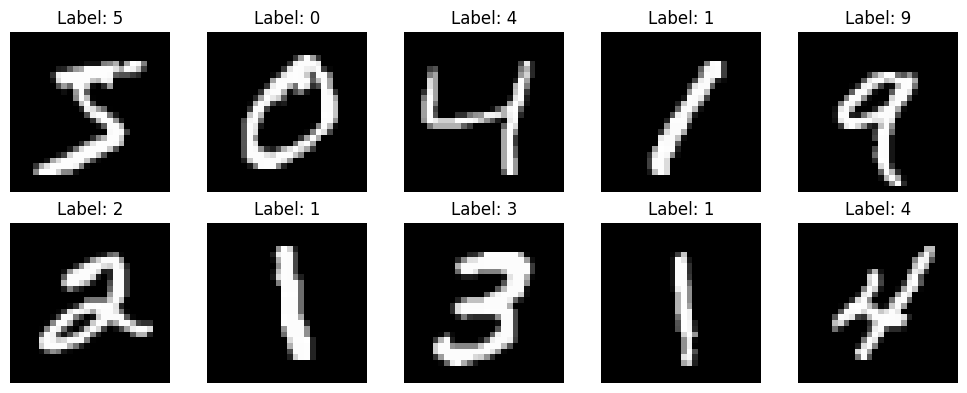

In [3]:
plt.figure(figsize=(10, 4))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    plt.title(f'Label: {y_train[i]}')
    plt.axis('off')
plt.tight_layout()
plt.show()

## 4. Preprocess the images

The original MNIST images are 28 × 28 pixels. The supplied architecture expects 32 × 32 images with one channel, so the images are resized and normalized to the range 0–1.

The resize operation also adds the channel dimension, producing the shape `(number_of_images, 32, 32, 1)`.

In [4]:
# Add a channel dimension, resize to 32 x 32, and normalize pixel values.
x_train = tf.image.resize(x_train[..., np.newaxis], (32, 32)) / 255.0
x_test = tf.image.resize(x_test[..., np.newaxis], (32, 32)) / 255.0

print('Processed training shape:', x_train.shape)
print('Processed test shape:', x_test.shape)
print('Pixel value range:', float(tf.reduce_min(x_train)), 'to', float(tf.reduce_max(x_train)))

Processed training shape: (60000, 32, 32, 1)
Processed test shape: (10000, 32, 32, 1)
Pixel value range: 0.0 to 1.0


## 5. Build the LeNet-5-style CNN

The model contains two convolutional layers, two average-pooling layers, and three dense layers. The final softmax layer returns probabilities for the 10 digit classes.

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(32, 32, 1)),
    tf.keras.layers.Conv2D(6, kernel_size=(5, 5), activation='tanh', padding='same'),
    tf.keras.layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
    tf.keras.layers.Conv2D(16, kernel_size=(5, 5), activation='tanh', padding='valid'),
    tf.keras.layers.AveragePooling2D(pool_size=(2, 2), strides=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(120, activation='tanh'),
    tf.keras.layers.Dense(84, activation='tanh'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 32, 32, 6)      │           156 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d               │ (None, 16, 16, 6)      │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 12, 12, 16)     │         2,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ average_pooling2d_1             │ (None, 6, 6, 16)       │             0 │
│ (AveragePooling2D)              │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 576)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 120)            │        69,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 84)             │        10,164 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           850 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 82,826 (323.54 KB)

 Trainable params: 82,826 (323.54 KB)

 Non-trainable params: 0 (0.00 B)

## 6. Compile the model

- **Optimizer:** Adam updates the model weights during training.
- **Loss:** sparse categorical cross-entropy is suitable because the labels are integer class IDs (0–9).
- **Metric:** accuracy reports the proportion of correctly classified images.

In [6]:
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

## 7. Train the model

The model is trained for 10 epochs with a batch size of 32. A portion of the training data is reserved for validation. The test set is kept separate for the final evaluation.

In [7]:
history = model.fit(
    x_train,
    y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.1,
    verbose=1
)

Epoch 1/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 48s 27ms/step - accuracy: 0.9296 - loss: 0.2380 - val_accuracy: 0.9665 - val_loss: 0.1118
Epoch 2/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.9701 - loss: 0.0985 - val_accuracy: 0.9747 - val_loss: 0.0856
Epoch 3/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 82s 25ms/step - accuracy: 0.9793 - loss: 0.0675 - val_accuracy: 0.9752 - val_loss: 0.0818
Epoch 4/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 44s 26ms/step - accuracy: 0.9842 - loss: 0.0520 - val_accuracy: 0.9820 - val_loss: 0.0618
Epoch 5/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 42s 25ms/step - accuracy: 0.9869 - loss: 0.0411 - val_accuracy: 0.9822 - val_loss: 0.0630
Epoch 6/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 80s 24ms/step - accuracy: 0.9892 - loss: 0.0337 - val_accuracy: 0.9847 - val_loss: 0.0567
Epoch 7/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 43s 25ms/step - accuracy: 0.9913 - loss: 0.0270 - val_accuracy: 0.9833 - val_loss: 0.0562
Epoch 8/10
1688/1688 ━━━━━━━━━━━━━━━━━━━━ 44s 26ms/step - accuracy: 0.9916 -

## 8. Visualize training performance

The plots help compare training and validation accuracy and loss across epochs.

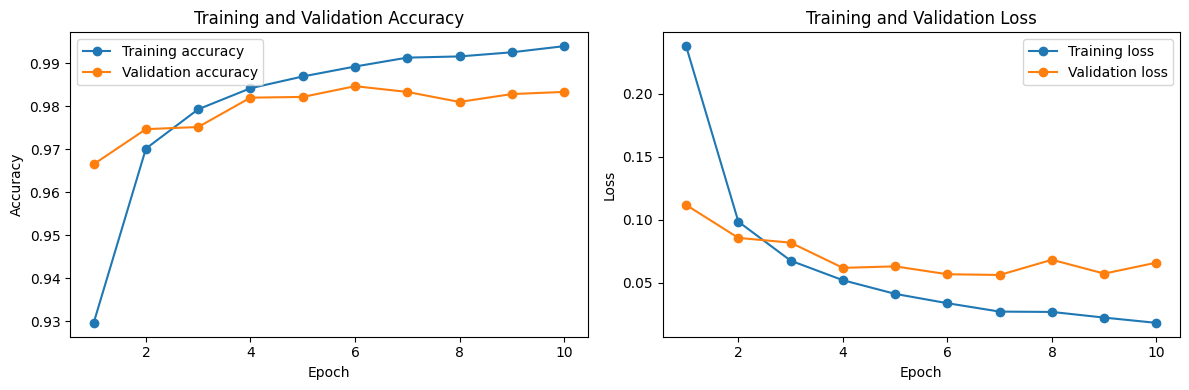

In [8]:
history_dict = history.history
epochs_range = range(1, len(history_dict['accuracy']) + 1)

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, history_dict['accuracy'], marker='o', label='Training accuracy')
plt.plot(epochs_range, history_dict['val_accuracy'], marker='o', label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(epochs_range, history_dict['loss'], marker='o', label='Training loss')
plt.plot(epochs_range, history_dict['val_loss'], marker='o', label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training and Validation Loss')
plt.legend()

plt.tight_layout()
plt.show()

## 9. Evaluate the model on the test dataset

This gives the final loss and accuracy on images that were not used for training or validation.

In [9]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss: {test_loss:.4f}')
print(f'Test accuracy: {test_accuracy * 100:.2f}%')

Test loss: 0.0629
Test accuracy: 98.24%


## 10. Make predictions

The model outputs 10 probabilities for each image. `argmax` selects the digit with the highest predicted probability.

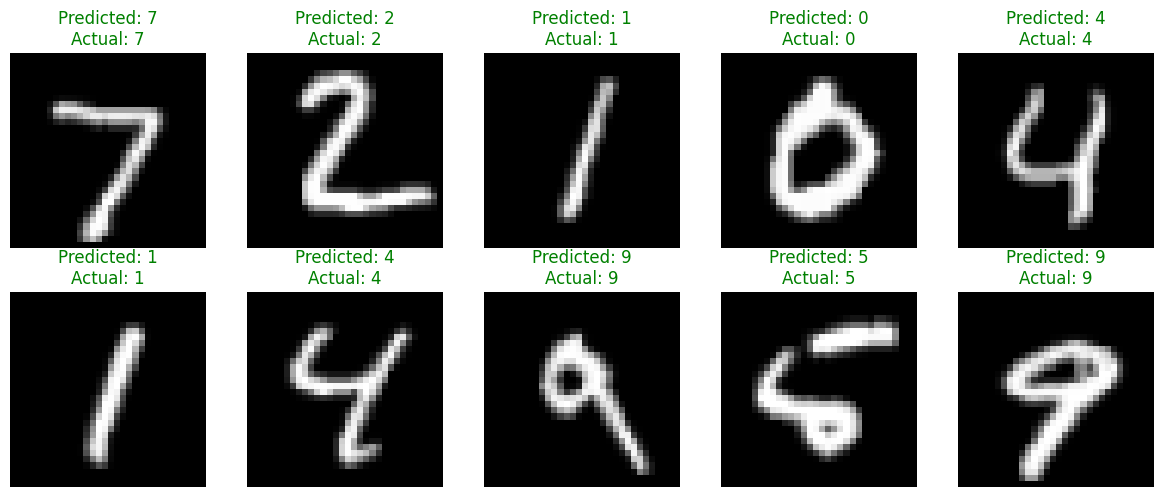

In [10]:
predicted_probabilities = model.predict(x_test[:10], verbose=0)
predicted_classes = np.argmax(predicted_probabilities, axis=1)

plt.figure(figsize=(12, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(tf.squeeze(x_test[i]), cmap='gray')
    color = 'green' if predicted_classes[i] == y_test[i] else 'red'
    plt.title(
        f'Predicted: {predicted_classes[i]}\nActual: {y_test[i]}',
        color=color
    )
    plt.axis('off')
plt.tight_layout()
plt.show()

## 11. Conclusion

The CNN has been trained to recognize handwritten digits from MNIST. Review the test accuracy and prediction examples to assess its performance.

### Suggested experiments
- Change the number of epochs and compare the results.
- Try a different batch size.
- Compare `tanh` with `relu` activation.
- Experiment with the number of filters in the convolutional layers.